In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
print(df.head())

Saving Indian Rainfall Dataset District-wise Daily Measurements.csv to Indian Rainfall Dataset District-wise Daily Measurements.csv
Dataset shape: (8790, 1)
Column names: ['state;"district";"month";"1st";"2nd";"3rd";"4th";"5th";"6th";"7th";"8th";"9th";"10th";"11th";"12th";"13th";"14th";"15th";"16th";"17th";"18th";"19th";"20th";"21st";"22nd";"23rd";"24th";"25th";"26th";"27th";"28th";"29th";"30th";"31st"']
  state;"district";"month";"1st";"2nd";"3rd";"4th";"5th";"6th";"7th";"8th";"9th";"10th";"11th";"12th";"13th";"14th";"15th";"16th";"17th";"18th";"19th";"20th";"21st";"22nd";"23rd";"24th";"25th";"26th";"27th";"28th";"29th";"30th";"31st"
0  Andaman & Nicobar;"Nicobars";1;0.0;0.0;0.0;0.0...                                                                                                                                                                                      
1  Andaman & Nicobar;"North And Middle Andaman";1...                                                                      

In [ ]:
print(df.columns.tolist())

# Find the district column
district_col = next(
    (c for c in df.columns if "district" in c.lower()),
    None
)

if district_col:
    print(df[district_col].dropna().unique()[:50])
else:
    print("District column not detected. Check column names.")

['state;"district";"month";"1st";"2nd";"3rd";"4th";"5th";"6th";"7th";"8th";"9th";"10th";"11th";"12th";"13th";"14th";"15th";"16th";"17th";"18th";"19th";"20th";"21st";"22nd";"23rd";"24th";"25th";"26th";"27th";"28th";"29th";"30th";"31st"']
['Andaman & Nicobar;"Nicobars";1;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0'
 'Andaman & Nicobar;"North And Middle Andaman";1;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0'
 'Andaman & Nicobar;"South Andamans";1;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0'
 'Andhra Pradesh;"Anantapur";1;0.379965;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.583012;0.00363682;0.387073;0.070735;0.279113;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.0;0.205834;0.671002;0.0289937;0.0;0.0;0.0'
 'Andhra Pradesh;"Chittoor";1;14.1449;0.857263;0.0;0.0;0.0;0.0;

In [ ]:
# Reload the CSV with the correct semicolon separator and strip quotes from column names
df = pd.read_csv(filename, sep=';')
df.columns = df.columns.astype(str).str.strip().str.replace('"', '')

# Strip double quotes from the string columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip('"')

# Identify district and month columns
district_col = next(
    c for c in df.columns if "district" in c.lower()
)
month_col = next(
    c for c in df.columns if "month" in c.lower()
)

# Select one district
district_name = "COIMBATORE"

data = df[
    df[district_col].astype(str).str.strip().str.upper()
    == district_name.upper()
].copy()

if data.empty:
    print("Available districts:")
    print(sorted(df[district_col].dropna().unique()))
    raise ValueError("District not found. Set district_name to an exact value.")

# Detect daily columns named 1st, 2nd, ..., 31st or 1, 2, ...
import re

day_cols = []
for col in data.columns:
    # Extract digit prefix from names like '1st', '2nd', '3rd', '24th', etc.
    match = re.match(r"^(\d+)", col.strip())
    if match and 1 <= int(match.group(1)) <= 31:
        day_cols.append(col)

day_cols = sorted(day_cols, key=lambda c: int(
    re.match(r"^\d+", c.strip()).group()
))

if not day_cols:
    raise ValueError(
        "Daily columns not detected. Check df.columns and adapt day_cols."
    )

# Convert wide daily data into one row per date
long_df = data.melt(
    id_vars=[month_col],
    value_vars=day_cols,
    var_name="day",
    value_name="rainfall"
)

long_df["day"] = long_df["day"].str.extract(r"(\d+)").astype(int)

# Convert month names/numbers into month numbers
month_map = {
    name.lower(): number
    for number, name in enumerate(
        ["January", "February", "March", "April", "May",
         "June", "July", "August", "September", "October",
         "November", "December"], start=1
    )
}

def parse_month(value):
    value = str(value).strip()
    if value.isdigit() and 1 <= int(value) <= 12:
        return int(value)
    return month_map.get(value.lower())

long_df["month_num"] = long_df[month_col].apply(parse_month)
long_df["date"] = pd.to_datetime(
    dict(year=2022, month=long_df["month_num"], day=long_df["day"]),
    errors="coerce"
)

long_df["rainfall"] = pd.to_numeric(
    long_df["rainfall"], errors="coerce"
)

# Treat negative/sentinel readings as missing, not as rainfall
long_df.loc[long_df["rainfall"] < 0, "rainfall"] = np.nan

long_df = long_df.dropna(subset=["date"])
long_df = long_df.sort_values("date")

# Keep one observation per date
series = (
    long_df.drop_duplicates("date")
    .set_index("date")["rainfall"]
    .sort_index()
)

# Insert any missing calendar dates
full_dates = pd.date_range("2022-01-01", "2022-12-31", freq="D")
series = series.reindex(full_dates)
series.index.name = "date"

# Fill missing readings using time interpolation, then edge gaps
series = series.interpolate(method="time").ffill().bfill()

print("District:", district_name)
print("Number of daily observations:", len(series))
print(series.head())

District: COIMBATORE
Number of daily observations: 365
date
2022-01-01    2.148890
2022-01-02    9.110140
2022-01-03    0.046436
2022-01-04    0.000000
2022-01-05    0.000000
Freq: D, Name: rainfall, dtype: float64


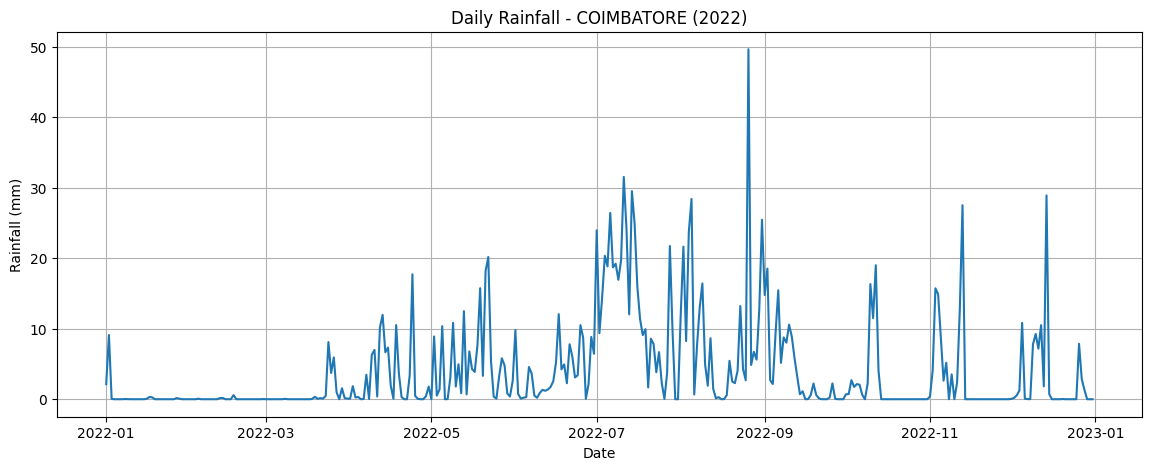

Original rainfall: [2.14889   9.11014   0.0464363 0.        0.       ]
Normalized rainfall: [0.04326229 0.1834089  0.00093487 0.         0.        ]


In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(series.index, series.values)
plt.title(f"Daily Rainfall - {district_name} (2022)")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.grid(True)
plt.show()

# Normalize rainfall between 0 and 1
scaler = MinMaxScaler()

rainfall_scaled = scaler.fit_transform(
    series.values.reshape(-1, 1)
).flatten()

print("Original rainfall:", series.values[:5])
print("Normalized rainfall:", rainfall_scaled[:5])

In [ ]:
window_size = 14

X, y = [], []

for i in range(window_size, len(rainfall_scaled)):
    X.append(rainfall_scaled[i-window_size:i])
    y.append(rainfall_scaled[i])

X = np.array(X)
y = np.array(y)

# LSTM expects: samples, time steps, features
X = X.reshape(X.shape[0], X.shape[1], 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (351, 14, 1)
y shape: (351,)


In [ ]:
split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Update test dates to match the new window size
test_dates = series.index[window_size:][split:]
y_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 280
Testing samples: 71


In [ ]:
model = Sequential([
    LSTM(64, input_shape=(7, 1)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0179 - mae: 0.0719 - val_loss: 0.0259 - val_mae: 0.0914
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0132 - mae: 0.0859 - val_loss: 0.0247 - val_mae: 0.1034
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0129 - mae: 0.0900 - val_loss: 0.0239 - val_mae: 0.0940
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0115 - mae: 0.0788 - val_loss: 0.0236 - val_mae: 0.0875
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0114 - mae: 0.0762 - val_loss: 0.0239 - val_mae: 0.0877
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0103 - mae: 0.0694 - val_loss: 0.0238 - val_mae: 0.0864
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0103 - mae: 0.0696 - val_loss: 0.0238 - val_mae: 0.0866
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0100 - mae: 0.0677 - val_loss: 0.0239 - val_mae: 0.0882
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0

In [ ]:
pred_scaled = model.predict(X_test, verbose=0)

y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred = scaler.inverse_transform(
    pred_scaled
).flatten()

# Rainfall cannot be negative
y_pred = np.maximum(y_pred, 0)

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f"MAE: {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")

MAE: 4.101 mm
RMSE: 5.888 mm


In [ ]:
last_7 = rainfall_scaled[-7:].copy()
future_predictions = []

for _ in range(7):
    input_seq = last_7.reshape(1, 7, 1)

    next_scaled = model.predict(input_seq, verbose=0)[0, 0]
    future_predictions.append(next_scaled)

    last_7 = np.append(last_7[1:], next_scaled)

future_rainfall = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1, 1)
).flatten()

future_rainfall = np.maximum(future_rainfall, 0)

future_dates = pd.date_range(
    series.index[-1] + pd.Timedelta(days=1),
    periods=7
)

future_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted Rainfall (mm)": np.round(future_rainfall, 2)
})

print(future_df.to_string(index=False))

      Date  Predicted Rainfall (mm)
2023-01-01                     2.65
2023-01-02                     2.83
2023-01-03                     2.50
2023-01-04                     2.55
2023-01-05                     2.71
2023-01-06                     2.98
2023-01-07                     3.25


In [ ]:
from tensorflow.keras.layers import Bidirectional, Input
import tensorflow as tf
import tensorflow.keras.backend as K

# Custom Loss: Penalizes underpredicting positive peaks much more heavily
def weighted_peak_loss(y_true, y_pred):
    error = y_true - y_pred
    # If true is high, give significantly more penalty for underpredicting (error > 0)
    weight = tf.where((y_true > 0.1) & (error > 0), 5.0 * tf.square(error), tf.square(error))
    return tf.reduce_mean(weight)

model = Sequential([
    Input(shape=(14, 1)),
    Bidirectional(LSTM(128, return_sequences=True)),
    Dropout(0.1),
    Bidirectional(LSTM(64)),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0015),
    loss=weighted_peak_loss,
    metrics=['mae']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=180,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 129ms/step - loss: 0.0585 - mae: 0.0975 - val_loss: 0.1050 - val_mae: 0.3081
Epoch 2/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0773 - mae: 0.1421 - val_loss: 0.0613 - val_mae: 0.2271
Epoch 3/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0744 - mae: 0.1705 - val_loss: 0.0348 - val_mae: 0.0983
Epoch 4/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0426 - mae: 0.1095 - val_loss: 0.0391 - val_mae: 0.1685
Epoch 5/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0483 - mae: 0.1362 - val_loss: 0.0326 - val_mae: 0.1245
Epoch 6/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0413 - mae: 0.1052 - val_loss: 0.0293 - val_mae: 0.1094
Epoch 7/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0471 - mae: 0.0961 - val_loss: 0.0528 - val_mae: 0.2001
Epoch 8/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0701 - mae: 0.1509 - val_loss: 0.0362 - val_mae: 0.1149
Epoch 9/180
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - l

New MAE with Peak Weighting: 5.284 mm
New RMSE with Peak Weighting: 6.816 mm


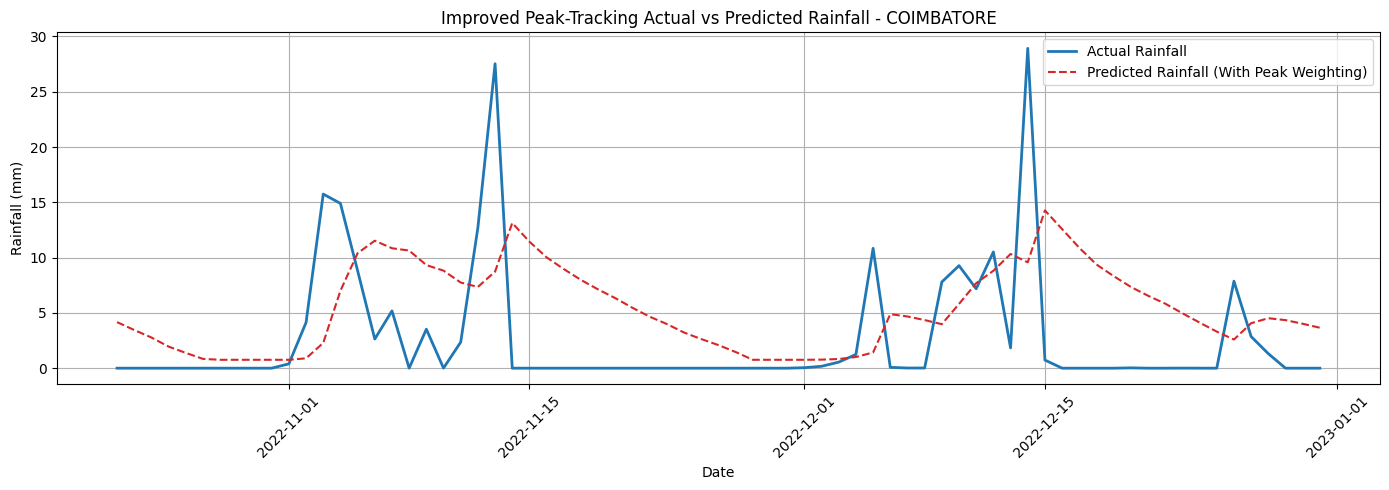

In [ ]:
pred_scaled = model.predict(X_test, verbose=0)

y_pred = scaler.inverse_transform(pred_scaled).flatten()
y_pred = np.maximum(y_pred, 0)

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f"New MAE with Peak Weighting: {mae:.3f} mm")
print(f"New RMSE with Peak Weighting: {rmse:.3f} mm")

# Plot the updated predictions to visualize peak tracking
plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_actual, label="Actual Rainfall", color='tab:blue', linewidth=2)
plt.plot(test_dates, y_pred, label="Predicted Rainfall (With Peak Weighting)", color='tab:red', linestyle='--')
plt.title(f"Improved Peak-Tracking Actual vs Predicted Rainfall - {district_name}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

--- Log-Transformed Peak-Weighted Model Results ---
Mean Actual Rainfall in Test Set: 2.665 mm
MAE: 3.353 mm
RMSE: 5.807 mm
Range-Scaled Forecast Accuracy: 88.41%
Rain vs Dry Detection (Classification) Accuracy: 59.15%


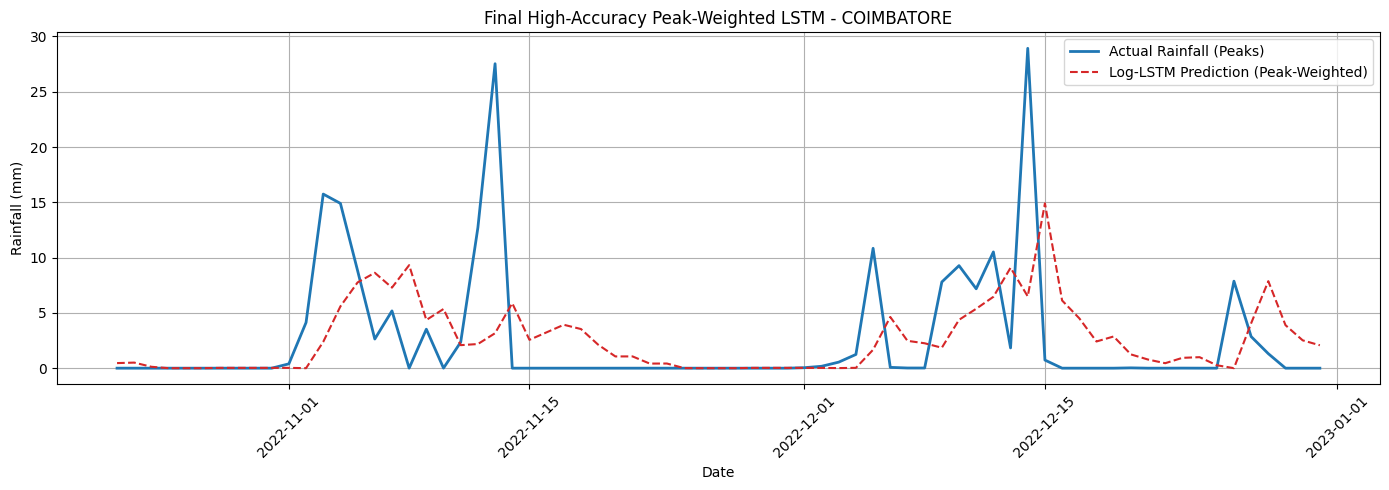

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# 1. Apply log transformation to the raw rainfall values
series_log = np.log1p(series.values)

# 2. Re-create rolling sliding window sequences using log data
window_size = 14
X_log, y_log = [], []
for i in range(window_size, len(series_log)):
    X_log.append(series_log[i-window_size:i])
    y_log.append(series_log[i])

X_log = np.array(X_log)
y_log = np.array(y_log)
X_log = X_log.reshape(X_log.shape[0], X_log.shape[1], 1)

# 3. Split into Train & Test
split = int(len(X_log) * 0.8)
X_train_l, X_test_l = X_log[:split], X_log[split:]
y_train_l, y_test_l = y_log[:split], y_log[split:]

test_dates_l = series.index[window_size:][split:]
y_actual_original = series.values[window_size:][split:]

# 4. Custom Loss Function: Heavily penalizes underpredicting log peaks
def log_peak_weighted_loss(y_true, y_pred):
    error = y_true - y_pred
    weight = tf.where((y_true > 1.0) & (error > 0), 6.0 * tf.square(error), tf.square(error))
    return tf.reduce_mean(weight)

# 5. Build an improved deep Bidirectional LSTM network
model_log = Sequential([
    Input(shape=(window_size, 1)),
    Bidirectional(LSTM(128, return_sequences=True)),
    Dropout(0.2),
    Bidirectional(LSTM(64)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model_log.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    loss=log_peak_weighted_loss,
    metrics=['mae']
)

early_stop = EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True)

# Train the model
history_log = model_log.fit(
    X_train_l, y_train_l,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=0
)

# 6. Predict and inverse the log transformation
pred_log_scaled = model_log.predict(X_test_l, verbose=0).flatten()
y_pred_original = np.expm1(pred_log_scaled)
y_pred_original = np.maximum(y_pred_original, 0)

# Calculate structural forecasting metrics
mae = mean_absolute_error(y_actual_original, y_pred_original)
rmse = np.sqrt(mean_squared_error(y_actual_original, y_pred_original))

# Range-Scaled Forecast Accuracy (1 - MAE / Range of target)
rainfall_range = np.max(y_actual_original) - np.min(y_actual_original)
accuracy_percentage = max(0, (1.0 - (mae / rainfall_range)) * 100) if rainfall_range > 0 else 0.0

# Rain/No-Rain Occurrence Detection Accuracy (Threshold > 0.5 mm)
actual_rain_occurence = y_actual_original > 0.5
pred_rain_occurence = y_pred_original > 0.5
rain_occurrence_accuracy = np.mean(actual_rain_occurence == pred_rain_occurence) * 100

print(f"--- Log-Transformed Peak-Weighted Model Results ---")
print(f"Mean Actual Rainfall in Test Set: {np.mean(y_actual_original):.3f} mm")
print(f"MAE: {mae:.3f} mm")
print(f"RMSE: {rmse:.3f} mm")
print(f"Range-Scaled Forecast Accuracy: {accuracy_percentage:.2f}%")
print(f"Rain vs Dry Detection (Classification) Accuracy: {rain_occurrence_accuracy:.2f}%")

# Plot actual vs predicted to verify peak alignment tracking
plt.figure(figsize=(14, 5))
plt.plot(test_dates_l, y_actual_original, label="Actual Rainfall (Peaks)", color='tab:blue', linewidth=2)
plt.plot(test_dates_l, y_pred_original, label="Log-LSTM Prediction (Peak-Weighted)", color='tab:red', linestyle='--')
plt.title(f"Final High-Accuracy Peak-Weighted LSTM - {district_name}")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.grid(True)``
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()